# 16. Vector Calculus

**Geometric Deep Learning — Mathematical Foundations**

This notebook follows Chapter 3, “Vector calculus” (pp. 26–36), of Borde and Bronstein, *Mathematical Foundations of Geometric Deep Learning*. It expands the chapter's central ideas with worked examples, short derivations, visualizations, and connections to machine learning. Apostol's *Calculus, Volume 2* is a supplementary reference for multivariable calculus and integral theorems.

## Learning objectives

- Distinguish continuity, Lipschitz continuity, differentiability, and smoothness.
- Understand scalar fields, vector fields, and signals.
- Compute and interpret gradients and Jacobians.
- Distinguish volume integrals and flux integrals.
- Interpret divergence and apply the divergence theorem.
- Derive the equation of continuity from conservation.
- Understand the Laplacian and gradient descent.
- Connect these ideas to neural networks, geometric learning, and scientific ML.

## 1. Continuity, Lipschitz continuity, differentiability, and smoothness

Let $f:\mathbb R^n\to\mathbb R^m$. Continuity says that sufficiently small input changes produce small output changes. Formally, $f$ is continuous at $x$ if for every $\varepsilon>0$ there exists $\delta>0$ such that

$$
\|x-y\|<\delta\implies \|f(x)-f(y)\|<\varepsilon.
$$

**Example:** $f(x)=x^2$ is continuous everywhere.

**Non-example:** $f(x)=0$ for $x<0$ and $f(x)=1$ for $x\geq0$ is discontinuous at $0$.

### 1.1 Lipschitz continuity

A function is Lipschitz on a domain if some $L\geq0$ satisfies

$$
\|f(x)-f(y)\|\leq L\|x-y\|
$$

for all points in the domain. The constant $L$ bounds the function's sensitivity. Every Lipschitz function is continuous, but the converse need not hold.

**Example:** $f(x)=3x+1$ is Lipschitz with $L=3$.

**Non-example:** $f(x)=\sqrt{x}$ is continuous on $[0,1]$, but not Lipschitz there: $|\sqrt{x}-\sqrt{0}|/|x-0|=1/\sqrt{x}$ is unbounded as $x\to0^+$.

### 1.2 Differentiability

A function is differentiable at $x$ if it has a linear first-order approximation:

$$
f(x+h)=f(x)+Df(x)h+o(\|h\|),\qquad h\to0.
$$

For scalar-valued functions the derivative is represented by the gradient; for vector-valued functions it is represented by the Jacobian.

**Example:** $f(x)=x^2$ has derivative $Df(x)h=2xh$.

**Non-example:** $f(x)=|x|$ is continuous but not differentiable at $0$, because its one-sided derivatives differ.

### 1.3 Smoothness

A function is $C^k$ if its derivatives through order $k$ exist and are continuous. It is smooth ($C^\infty$) if derivatives of all orders exist and are continuous.

These notions should not be conflated: continuity rules out jumps, Lipschitz continuity bounds changes, differentiability supplies a local linear model, and smoothness allows repeated differentiation. ReLU is continuous and Lipschitz but not differentiable at its kink.

## 2. Scalar fields, vector fields, and signals

A **scalar field** assigns a number to each point, $f:\Omega\subseteq\mathbb R^n\to\mathbb R$. Examples include temperature, pressure, or density.

A **vector field** assigns a vector to each point, $F:\Omega\subseteq\mathbb R^n\to\mathbb R^n$. Examples include fluid velocity and force.

A **signal** is a value associated with points of a domain. It may be scalar- or vector-valued. In ML, features on image grids, graphs, point clouds, and meshes can be viewed as signals on those domains.

For example, $f(x,y)=x^2+y^2$ is a scalar field, while $F(x,y)=(x,y)$ is a vector field pointing radially outward.

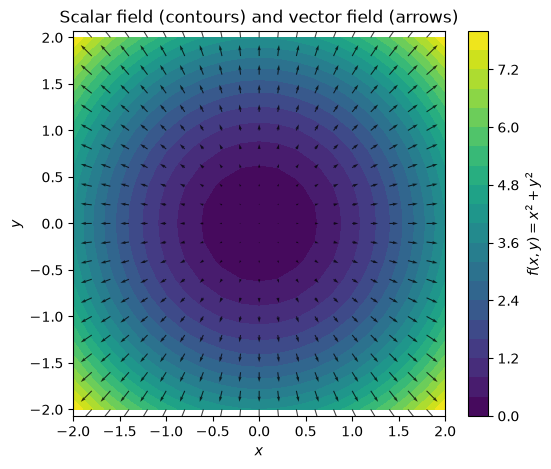

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-2, 2, 21)
y = np.linspace(-2, 2, 21)
X, Y = np.meshgrid(x, y)
f = X**2 + Y**2
U, V = X, Y

plt.figure(figsize=(6, 5))
plt.contourf(X, Y, f, levels=20)
plt.colorbar(label=r"$f(x,y)=x^2+y^2$")
plt.quiver(X, Y, U, V, color="black", alpha=0.75)
plt.xlabel("$x$"); plt.ylabel("$y$")
plt.title("Scalar field (contours) and vector field (arrows)")
plt.axis("equal"); plt.show()

## 3. Derivatives and gradients

### 3.1 Partial derivatives

The partial derivative of $f$ with respect to coordinate $x_i$ is

$$
\frac{\partial f}{\partial x_i}(x)
=\lim_{h\to0}\frac{f(x+he_i)-f(x)}{h},
$$

when the limit exists. For $f(x,y)=x^2y+3y$,

$$
\frac{\partial f}{\partial x}=2xy,\qquad
\frac{\partial f}{\partial y}=x^2+3.
$$

### 3.2 Gradient and directional derivatives

The gradient of a scalar field collects its partial derivatives:

$$
\nabla f(x)=
\begin{pmatrix}
\partial f/\partial x_1\\
\vdots\\
\partial f/\partial x_n
\end{pmatrix}.
$$

Under the Euclidean inner product, the gradient points in the direction of steepest local increase. The directional derivative along a unit vector $u$ is

$$
D_u f(x)=\nabla f(x)\cdot u,
\qquad
\max_{\|u\|=1}D_u f(x)=\|\nabla f(x)\|.
$$

The gradient is perpendicular to a regular level set $f(x)=c$: tangent motion along the level set does not change $f$ to first order.

**Example:** If $f(x,y)=x^2+y^2$, then $\nabla f=(2x,2y)$, normal to the circular level sets.

### 3.3 Jacobian

For $F:\mathbb R^n\to\mathbb R^m$, the Jacobian matrix is

$$
J_F(x)_{ij}=\frac{\partial F_i}{\partial x_j}(x).
$$

It describes the local linear response $F(x+h)\approx F(x)+J_F(x)h$.

For $F(x,y)=(x^2+y,xy)$,

$$
J_F(x,y)=
\begin{pmatrix}2x&1\\y&x\end{pmatrix}.
$$

At $(1,2)$, this becomes $\begin{pmatrix}2&1\\2&1\end{pmatrix}$.

### Exercises

1. Find $\nabla f$ for $f(x,y,z)=x^2+2y^2+3z^2$.
2. Find the Jacobian of $F(x,y)=(xy,x+y^2)$.
3. Explain why the gradient is normal to a regular level curve.

## 4. Integrals of fields

Integration aggregates local values across a domain.

### 4.1 Volume integrals

For a scalar field $\rho$ on a region $\Omega\subseteq\mathbb R^3$,

$$
\iiint_\Omega \rho(x)\,dV
$$

adds the quantity throughout the volume. If $\rho$ is mass density, the result is total mass.

### 4.2 Line integrals

For a curve $\gamma:[a,b]\to\mathbb R^n$ and vector field $F$,

$$
\int_\gamma F\cdot d\mathbf r
=\int_a^b F(\gamma(t))\cdot\gamma'(t)\,dt.
$$

This measures the component of the field along the path; in mechanics, it describes work by a force.

### 4.3 Surface flux

For a surface $S$ with unit normal $n$,

$$
\iint_S F\cdot n\,dS
$$

measures net flow through the surface. The sign depends on orientation: positive means flow along the chosen normal, negative means flow against it.

**Example:** For $F=(0,0,c)$ through a horizontal square of area $A$ with upward normal, the flux is $cA$. Reversing the normal changes it to $-cA$.

## 5. Divergence and the divergence theorem

For a differentiable vector field $F=(F_1,\ldots,F_n)$, divergence is the scalar field

$$
\nabla\cdot F=\operatorname{div}F
=\sum_{i=1}^n\frac{\partial F_i}{\partial x_i}.
$$

In three dimensions,

$$
\nabla\cdot F=
\frac{\partial F_1}{\partial x}
+\frac{\partial F_2}{\partial y}
+\frac{\partial F_3}{\partial z}.
$$

Divergence measures local net outward flux per unit volume. Positive divergence is source-like; negative divergence is sink-like; zero divergence means no local net expansion of flux. A divergence-free field can still have nonzero flux through individual pieces of a boundary.

**Examples**

For $F(x,y,z)=(x,y,z)$, $\nabla\cdot F=3$. For $F(x,y,z)=(-y,x,0)$, $\nabla\cdot F=0$ even though the field circulates around the $z$-axis.

### 5.1 Divergence theorem

Let $\Omega\subseteq\mathbb R^3$ be a bounded region with sufficiently regular closed boundary $\partial\Omega$, oriented by the outward unit normal $n$. For a continuously differentiable field $F$,

$$
\boxed{\iiint_\Omega \nabla\cdot F\,dV
=\iint_{\partial\Omega}F\cdot n\,dS.}
$$

The integral of local divergence over the volume equals the net outward flux across the boundary. The theorem connects a local differential description with a global boundary measurement.

### 5.2 Worked example: a ball

Take $F(x,y,z)=(x,y,z)$ on a ball of radius $R$. Since $\nabla\cdot F=3$,

$$
\iiint_\Omega \nabla\cdot F\,dV
=3\frac{4}{3}\pi R^3=4\pi R^3.
$$

On the sphere, $n=(x,y,z)/R$, so $F\cdot n=R$. Therefore

$$
\iint_{\partial\Omega}F\cdot n\,dS
=R(4\pi R^2)=4\pi R^3.
$$

Both sides agree.

## 6. The equation of continuity

The divergence theorem is central to conservation laws. Let $\rho(x,t)$ be the density of a conserved quantity and $v(x,t)$ its velocity field. The amount inside a fixed region $\Omega$ is

$$
M_\Omega(t)=\iiint_\Omega \rho(x,t)\,dV.
$$

Conservation says that the rate of change inside the region equals minus the net outward flux:

$$
\frac{d}{dt}\iiint_\Omega \rho\,dV
=-\iint_{\partial\Omega}\rho v\cdot n\,dS.
$$

Assuming sufficient regularity, move the time derivative inside the integral and apply the divergence theorem to $\rho v$:

$$
\iiint_\Omega \frac{\partial\rho}{\partial t}\,dV
=-\iiint_\Omega \nabla\cdot(\rho v)\,dV.
$$

Since this holds for arbitrary suitable regions, the local **equation of continuity** is

$$
\boxed{\frac{\partial\rho}{\partial t}+\nabla\cdot(\rho v)=0.}
$$

This equation expresses local conservation in the absence of sources and sinks.

### 6.1 Incompressible flow

If $\rho$ is constant and positive, the continuity equation reduces to

$$
\nabla\cdot v=0.
$$

Thus a smooth incompressible velocity field is divergence-free. More generally, the full continuity equation is needed when density varies.

### 6.2 Sources and sinks

If a quantity is created at rate $s(x,t)$ per unit volume, then

$$
\frac{\partial\rho}{\partial t}+\nabla\cdot(\rho v)=s.
$$

### 6.3 One-dimensional transport

In one dimension,

$$
\frac{\partial\rho}{\partial t}
+\frac{\partial}{\partial x}(\rho v)=0.
$$

For constant velocity $v=c$, this becomes $\partial_t\rho+c\partial_x\rho=0$: the initial density profile travels at speed $c$ without changing shape.

**Conceptual chain:** conservation in a region → boundary flux → divergence theorem → local differential equation.

## 7. The Laplacian

For a twice-differentiable scalar field $f$, the Laplacian is the divergence of its gradient:

$$
\boxed{\Delta f=\nabla\cdot\nabla f.}
$$

In Euclidean coordinates,

$$
\Delta f=\sum_{i=1}^n\frac{\partial^2f}{\partial x_i^2}.
$$

It measures a local imbalance relative to nearby values. A function is harmonic if $\Delta f=0$.

For $f(x,y)=x^2+y^2$, $\Delta f=4$. For $g(x,y)=x^2-y^2$, $\Delta g=2-2=0$, so $g$ is harmonic.

The Laplacian appears in diffusion and heat equations, potential theory, smoothing, and spectral methods. On a graph, the combinatorial Laplacian $L=D-A$ plays an analogous role, though its meaning depends on the graph and chosen normalization.

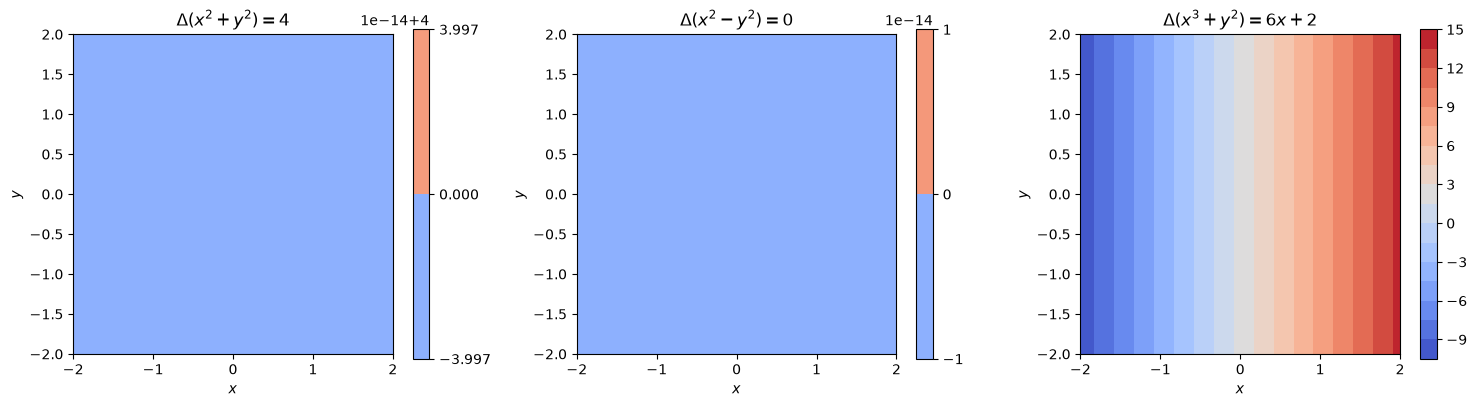

In [5]:
x = np.linspace(-2, 2, 100)
y = np.linspace(-2, 2, 100)
X, Y = np.meshgrid(x, y)

# Laplacians of three scalar fields
lap_f = np.full_like(X, 4.0)       # f(x, y) = x^2 + y^2
lap_g = np.zeros_like(X)           # g(x, y) = x^2 - y^2
lap_h = 6 * X + 2                  # h(x, y) = x^3 + y^2

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, Z, title in [
    (axes[0], lap_f, r"$\Delta(x^2+y^2)=4$"),
    (axes[1], lap_g, r"$\Delta(x^2-y^2)=0$"),
    (axes[2], lap_h, r"$\Delta(x^3+y^2)=6x+2$"),
]:
    im = ax.contourf(X, Y, Z, levels=20, cmap="coolwarm")
    fig.colorbar(im, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## 8. Gradient descent optimization in deep learning

Let $L(\theta)$ be a differentiable loss function on parameters $\theta\in\mathbb R^p$. The gradient points in the direction of steepest local increase under the Euclidean metric, so gradient descent steps oppositely:

$$
\boxed{\theta_{t+1}=\theta_t-\alpha\nabla_\theta L(\theta_t),}
$$

where $\alpha>0$ is the learning rate. The chain rule lets gradients propagate through compositions of neural-network layers.

For $L(\theta)=(\theta-3)^2$, the derivative is $2(\theta-3)$ and the update is

$$
\theta_{t+1}=\theta_t-2\alpha(\theta_t-3).
$$

For $0<\alpha<1$, the iteration converges to $3$ in exact arithmetic.

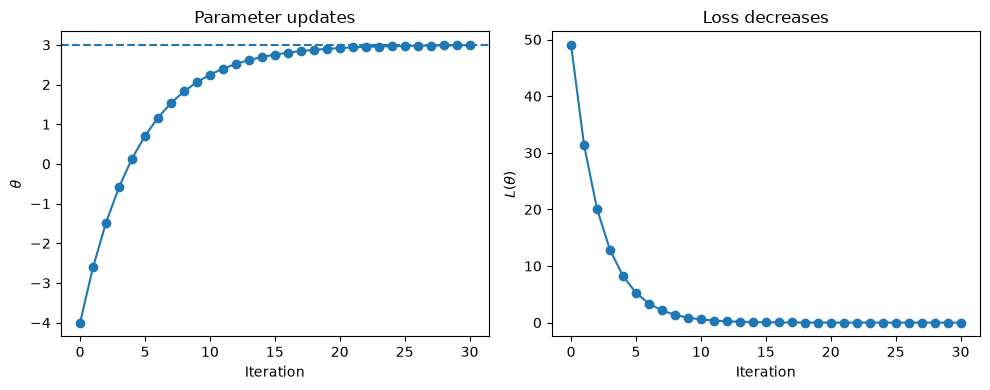

Final theta: 2.991334
Final loss: 0.00007509


In [6]:
theta = -4.0
learning_rate = 0.1
num_steps = 30
theta_history = [theta]
loss_history = [(theta - 3.0)**2]

for _ in range(num_steps):
    grad = 2 * (theta - 3.0)
    theta -= learning_rate * grad
    theta_history.append(theta)
    loss_history.append((theta - 3.0)**2)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(theta_history, marker="o")
axes[0].axhline(3.0, linestyle="--")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel(r"$\theta$")
axes[0].set_title("Parameter updates")
axes[1].plot(loss_history, marker="o")
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel(r"$L(\theta)$")
axes[1].set_title("Loss decreases")
plt.tight_layout(); plt.show()
print(f"Final theta: {theta:.6f}")
print(f"Final loss: {(theta - 3.0)**2:.8f}")

## 9. Connection with Machine Learning

This section gathers and expands the chapter's machine-learning connections into one place.

### 9.1 Fields as learned representations

A scalar or vector field assigns values to points in a domain. A neural network can learn such a function: coordinates may be inputs and scalar values, vectors, or feature vectors may be outputs. This viewpoint appears in implicit neural representations, physical-field prediction, and 3D learning.

The domain need not be a regular grid. Features on graphs, point clouds, meshes, and manifolds are signals on structured domains. The domain geometry affects which operations are meaningful and which symmetries a model should respect.

### 9.2 Continuity, Lipschitz bounds, and stability

A Lipschitz model satisfies $\|f(x)-f(y)\|\leq L\|x-y\|$. This bounds output sensitivity to input perturbations and is relevant to stability and robustness analysis, although it does not by itself guarantee generalization or adversarial robustness. ReLU networks are continuous and Lipschitz, but not differentiable at their activation kinks.

### 9.3 Gradients, Jacobians, and backpropagation

The gradient $\nabla_\theta L$ drives gradient-based optimization. The Jacobian describes local sensitivity, $F(x+h)\approx F(x)+J_F(x)h$. Automatic differentiation applies the chain rule to the computational graph; in practice, vector-Jacobian products often avoid forming the full Jacobian.

### 9.4 Integrals and aggregate quantities

Integrals turn local quantities into global ones. In ML and scientific computing, they appear in expected losses, continuous probability densities, physical energies, and spatial aggregation. Numerical methods approximate integrals by sums or quadrature, introducing sampling and discretization choices.

### 9.5 Divergence, conservation, and physics-informed learning

A model that predicts density $\rho$ and velocity $v$ can be encouraged to respect the continuity equation:

$$
\frac{\partial\rho}{\partial t}+\nabla\cdot(\rho v)=0.
$$

Define the residual

$$
r(x,t)=\frac{\partial\rho}{\partial t}+\nabla\cdot(\rho v).
$$

A physics-informed objective may include

$$
\mathcal L_{\mathrm{continuity}}
=\frac1N\sum_{i=1}^N |r(x_i,t_i)|^2.
$$

This is a soft constraint; some applications instead require conservative discretizations or architectural guarantees.

### 9.6 Laplacian, smoothness, and geometric learning

For an undirected graph with adjacency $A$ and degree matrix $D$, the combinatorial graph Laplacian is $L=D-A$. For a scalar vertex signal $x$,

$$
x^\top Lx=\frac12\sum_{i,j}A_{ij}(x_i-x_j)^2.
$$

This energy penalizes differences across adjacent vertices, giving a discrete analogue of continuous gradient energy. Graph Laplacians are used in smoothing, spectral methods, and graph representation learning; normalization and graph weights affect the operator's interpretation.

### 9.7 Optimization geometry

The ordinary gradient depends on the inner product used to define steepest descent. On manifolds or in non-Euclidean parameter spaces, the appropriate gradient can differ from the Euclidean one. Geometric ideas therefore inform optimization as well as model architecture.

**Summary:** derivatives describe local variation; integrals aggregate local quantities; divergence describes net flow; the continuity equation encodes conservation; the Laplacian describes local variation and diffusion; and gradients drive learning.

## 10. Exercises

### Conceptual
1. Give a continuous function that is not Lipschitz on its domain.
2. Explain the difference between a scalar field and a vector field.
3. Can a vector field have zero divergence and nonzero circulation? Give an example.
4. Explain why the divergence theorem is related to conservation.
5. Under what assumption does the continuity equation reduce to $\nabla\cdot v=0$?

### Computation
1. Compute $\nabla f$ for $f(x,y,z)=xy+yz+zx$.
2. Compute $\nabla\cdot F$ for $F(x,y,z)=(x^2,y^2,z^2)$.
3. Compute $\Delta f$ for $f(x,y,z)=x^2+y^2-z^2$.
4. Verify the divergence theorem for $F(x,y,z)=(x,y,z)$ on a ball of radius $R$.
5. Solve $\partial_t\rho+c\partial_x\rho=0$ by identifying its characteristic curves.

### Coding task
Use finite differences to approximate the gradient of $f(x,y)=x^2+3y^2$ at a point. Compare with the exact gradient and investigate how the error changes as the step size decreases. Very small steps can amplify floating-point roundoff.

## References

1. Haitz Sáez de Ocáriz Borde and Michael Bronstein, *Mathematical Foundations of Geometric Deep Learning*, Chapter 3, “Vector calculus,” §§3.1–3.7, pp. 26–36. [arXiv:2508.02723](https://arxiv.org/abs/2508.02723).
2. Tom M. Apostol, *Calculus, Volume 2*, 2nd ed., Wiley. Supplementary reference for differential calculus of scalar and vector fields, line integrals, and integral theorems. [Publisher page](https://www.wiley.com/en-in/calculus-volume-2-2nd-edition-p-9781119496762).

This notebook is an explanatory companion rather than a verbatim reproduction. The exposition is paraphrased and expanded with examples, derivations, exercises, and computational illustrations.